# Yukon River basin precipitation undercatch

Corrected station files for Canada and the United States, 1980–2019.
`original_prcp` is the series before the undercatch adjustment. `prcp` is the
series after it. Canada uses the SPICE catch-efficiency correction for an
unshielded gauge, with no adjustment above 5°C. The United States uses Newman
et al. (2020): a Goodison snowfall adjustment, and no rainfall adjustment.
Both methods leave dry days dry and do not reduce precipitation.

On a wet day the correction factor is `prcp / original_prcp`. The station
factor is the ratio of the two 40-year totals, which is the precipitation-weighted
effect at that station. Stations whose precipitation record is entirely missing
are counted and then left out of the figures.

Figures are sized for a double journal column and written to `figs/yrb_undercatch/`
as PDF and 300 dpi PNG. The maps use the Yukon River basin domain DEM in the
same way as `plot_dem_with_two_stations`: a `Greys` image, a black outline,
then stations.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import seaborn as sns
import xarray as xr
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter, MultipleLocator
from rasterio.enums import Resampling
from shapely.geometry import box

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "axes.linewidth": 0.6,
    "axes.unicode_minus": False,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.04,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

STATION_FILES = {
    "CA": Path("/Users/dcasson/Data/gpep/yrb/data_prep/stations/undercatch_files/CA/corrected_stations.nc"),
    "US": Path("/Users/dcasson/Data/gpep/yrb/data_prep/stations/undercatch_files/US/corrected_stations.nc"),
}
DEM_PATH = Path("/Users/dcasson/Data/gpep/yrb/data_prep/dem/domain_dem.tif")
COAST_PATH = Path("/Users/dcasson/Data/GISData/coastline/ne_10m_coastline.shp")
COUNTRIES_PATH = Path("/Users/dcasson/Data/GISData/World_Countries.gpkg")
FIG_DIR = Path(
    "/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch"
)
N_YEARS = 40

COUNTRIES = [
    {"key": "CA", "label": "Canada, SPICE", "short": "Canada", "color": "#0072B2"},
    {"key": "US", "label": "United States, Newman 2020", "short": "United States", "color": "#D55E00"},
]
SHORT = [spec["short"] for spec in COUNTRIES]
PALETTE = {spec["short"]: spec["color"] for spec in COUNTRIES}
MONTH_LABELS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]


def save_figure(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    png = FIG_DIR / f"{name}.png"
    pdf = FIG_DIR / f"{name}.pdf"
    fig.savefig(png)
    fig.savefig(pdf)
    print(png)
    print(pdf)


def style_distribution_axis(ax):
    ax.tick_params(direction="out", length=3, width=0.6)
    ax.yaxis.grid(True, linestyle=":", linewidth=0.4, color="0.75", zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlabel("")


def panel_letter(ax, letter, pad_box=False):
    kwargs = dict(
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        fontweight="bold",
        zorder=6,
    )
    if pad_box:
        kwargs["bbox"] = dict(
            boxstyle="square,pad=0.12",
            facecolor="white",
            edgecolor="none",
            alpha=0.9,
        )
    ax.text(0.02, 0.98, letter, **kwargs)


def binned_curve(x, y, edges, min_count):
    centers = []
    p25 = []
    p50 = []
    p75 = []
    for lower, upper in zip(edges[:-1], edges[1:]):
        if upper == edges[-1]:
            chosen = (x >= lower) & (x <= upper) & np.isfinite(x) & np.isfinite(y)
        else:
            chosen = (x >= lower) & (x < upper) & np.isfinite(x) & np.isfinite(y)
        if int(chosen.sum()) < min_count:
            centers.append(np.nan)
            p25.append(np.nan)
            p50.append(np.nan)
            p75.append(np.nan)
            continue
        sample = y[chosen]
        centers.append(0.5 * (lower + upper))
        p25.append(float(np.percentile(sample, 25)))
        p50.append(float(np.percentile(sample, 50)))
        p75.append(float(np.percentile(sample, 75)))
    return map(np.asarray, (centers, p25, p50, p75))

### Station series

Temperature and wind are the observed value where it exists and the filled
value otherwise. That is the pair the correction was applied with. A station
enters the figures only when both precipitation series are finite on every day.

In [5]:
def load_country(spec):
    with xr.open_dataset(STATION_FILES[spec["key"]]) as dataset:
        original = np.asarray(dataset["original_prcp"].values, dtype=np.float64)
        corrected = np.asarray(dataset["prcp"].values, dtype=np.float64)
        temperature = np.asarray(dataset["tmean"].values, dtype=np.float64)
        temperature_filled = np.asarray(dataset["tmean_filled"].values, dtype=np.float64)
        wind = np.asarray(dataset["wind"].values, dtype=np.float64)
        wind_filled = np.asarray(dataset["wind_filled"].values, dtype=np.float64)
        latitude = np.asarray(dataset["latitude"].values, dtype=np.float64)
        longitude = np.asarray(dataset["longitude"].values, dtype=np.float64)
        elevation = np.asarray(dataset["elevation"].values, dtype=np.float64)
        time = pd.to_datetime(dataset["time"].values)
        method = str(dataset.attrs.get("undercatch_correction_type", spec["label"]))

    #if len(time) != N_YEARS * 365 + 10 or int(time.year.min()) != 1980 or int(time.year.max()) != 2025:
    #    raise ValueError(f"{spec['key']} does not cover 1980–2019 at daily resolution")

    finite = np.isfinite(original).all(axis=1) & np.isfinite(corrected).all(axis=1)
    temperature = np.where(np.isfinite(temperature), temperature, temperature_filled)
    wind = np.where(np.isfinite(wind), wind, wind_filled)
    n_missing = int((~finite).sum())
    original = original[finite]
    corrected = corrected[finite]
    temperature = temperature[finite]
    wind = wind[finite]
    wet = original > 0
    if np.nanmin(corrected - original) < -1e-3:
        raise ValueError(f"{spec['key']} correction reduced precipitation")

    station_factor = corrected.sum(axis=1) / original.sum(axis=1)
    added_mm_yr = (corrected - original).sum(axis=1) / N_YEARS
    frame = pd.DataFrame({
        "key": spec["key"],
        "label": spec["label"],
        "short": spec["short"],
        "latitude": latitude[finite],
        "longitude": longitude[finite],
        "elevation_m": elevation[finite],
        "station_factor": station_factor,
        "increase_pct": (station_factor - 1.0) * 100.0,
        "added_mm_yr": added_mm_yr,
        "original_mm_yr": original.sum(axis=1) / N_YEARS,
        "corrected_mm_yr": corrected.sum(axis=1) / N_YEARS,
    })
    print(
        f"{spec['short']}: {method}; {int(finite.sum())} stations with a full record, "
        f"{n_missing} with no precipitation"
    )
    return {
        "original": original,
        "corrected": corrected,
        "temperature": temperature,
        "wind": wind,
        "wet": wet,
        "time": time,
        "n_missing": n_missing,
        "pooled_factor": float(corrected.sum() / original.sum()),
    }, frame


daily = {}
frames = []
for spec in COUNTRIES:
    country_daily, frame = load_country(spec)
    daily[spec["key"]] = country_daily
    frames.append(frame)

stations = pd.concat(frames, ignore_index=True)
print(
    "Longitude {west:.2f} to {east:.2f}, latitude {south:.2f} to {north:.2f}".format(
        west=stations["longitude"].min(),
        east=stations["longitude"].max(),
        south=stations["latitude"].min(),
        north=stations["latitude"].max(),
    )
)

Canada: CA:SPICE; 79 stations with a full record, 53 with no precipitation
United States: US:NEWMAN2020; 262 stations with a full record, 189 with no precipitation
Longitude -166.80 to -126.16, latitude 54.01 to 71.32


### Summary

The wet-day median treats every wet day equally, so the many warm days with a
factor of 1 pull it toward 1. The pooled factor is the ratio of the two
precipitation totals over all complete stations. The station median is the
typical gauge.

In [6]:
rows = []
for spec in COUNTRIES:
    part = stations.loc[stations["key"] == spec["key"]]
    sample = daily[spec["key"]]
    wet_factor = sample["corrected"][sample["wet"]] / sample["original"][sample["wet"]]
    rows.append({
        "Country": spec["short"],
        "Method": "SPICE" if spec["key"] == "CA" else "Newman 2020",
        "N": int(len(part)),
        "No precip.": int(sample["n_missing"]),
        "Wet-day median": float(np.median(wet_factor)),
        "Share unchanged": float(np.mean(np.isclose(wet_factor, 1.0, atol=1e-3))),
        "Pooled factor": sample["pooled_factor"],
        "Median station factor": float(part["station_factor"].median()),
        "Median increase (%)": float(part["increase_pct"].median()),
        "Median added (mm/yr)": float(part["added_mm_yr"].median()),
        "P95 added (mm/yr)": float(part["added_mm_yr"].quantile(0.95)),
    })

summary = pd.DataFrame(rows)
FIG_DIR.mkdir(parents=True, exist_ok=True)
summary.to_csv(FIG_DIR / "undercatch_summary.csv", index=False)
stations.to_csv(FIG_DIR / "undercatch_stations.csv", index=False)

integer_cols = {"N", "No precip."}
one_decimal = {"Median increase (%)", "Median added (mm/yr)", "P95 added (mm/yr)"}
formats = {}
for column in summary.columns:
    if column in integer_cols or column in ("Country", "Method"):
        continue
    if column == "Share unchanged":
        formats[column] = "{:.1%}"
    elif column in one_decimal:
        formats[column] = "{:.1f}"
    else:
        formats[column] = "{:.3f}"
display(summary.style.format(formats).hide(axis="index"))

Country,Method,N,No precip.,Wet-day median,Share unchanged,Pooled factor,Median station factor,Median increase (%),Median added (mm/yr),P95 added (mm/yr)
Canada,SPICE,79,53,1.007,50.0%,1.144,1.166,16.6,97.6,287.3
United States,Newman 2020,262,189,1.002,49.0%,1.280,1.148,14.8,87.1,1206.6


### Corrected precipitation against the original series

Each panel is wet days in that season. The dashed line is unchanged precipitation.
Axes stop at 80 mm/day. A few heavier days, mostly winter days in the United States,
fall outside the frame. Color is the number of wet days in each hexagon,
on one logarithmic scale.

/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_daily_comparison.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_daily_comparison.pdf


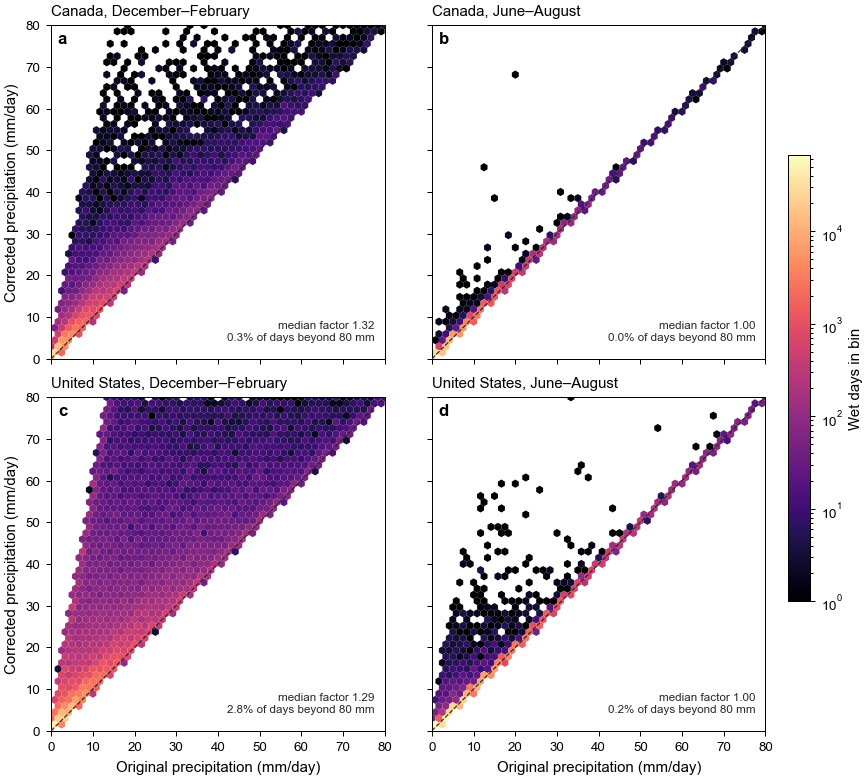

In [7]:
AXIS_LIMIT = 80
seasons = [
    ("DJF", (12, 1, 2), "December–February"),
    ("JJA", (6, 7, 8), "June–August"),
]

fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.5), constrained_layout=True, sharex=True, sharey=True)
hexbin_artists = []
for row, spec in enumerate(COUNTRIES):
    sample = daily[spec["key"]]
    months = sample["time"].month.to_numpy()
    for column, (season_key, season_months, season_label) in enumerate(seasons):
        ax = axes[row, column]
        chosen = sample["wet"] & np.isin(months, season_months)
        original = sample["original"][chosen]
        corrected = sample["corrected"][chosen]
        in_frame = (original <= AXIS_LIMIT) & (corrected <= AXIS_LIMIT)
        artist = ax.hexbin(
            original[in_frame],
            corrected[in_frame],
            gridsize=48,
            mincnt=1,
            extent=(0, AXIS_LIMIT, 0, AXIS_LIMIT),
            linewidths=0,
            cmap="magma",
            zorder=1,
        )
        hexbin_artists.append(artist)
        ax.plot([0, AXIS_LIMIT], [0, AXIS_LIMIT], color="0.15", lw=0.7, ls="--", zorder=3)
        ax.set_xlim(0, AXIS_LIMIT)
        ax.set_ylim(0, AXIS_LIMIT)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{spec['short']}, {season_label}", loc="left")
        median_factor = float(np.median(corrected / original))
        outside = 1.0 - float(in_frame.mean())
        ax.text(
            0.97,
            0.05,
            f"median factor {median_factor:.2f}\n{outside:.1%} of days beyond {AXIS_LIMIT:.0f} mm",
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=7,
            color="0.15",
        )
        panel_letter(ax, "abcd"[row * 2 + column], pad_box=True)
        ax.tick_params(direction="out", length=3, width=0.6)
        for spine in ax.spines.values():
            spine.set_visible(True)

for ax in axes[:, 0]:
    ax.set_ylabel("Corrected precipitation (mm/day)")
for ax in axes[1, :]:
    ax.set_xlabel("Original precipitation (mm/day)")

count_max = max(float(np.nanmax(artist.get_array())) for artist in hexbin_artists)
count_norm = LogNorm(vmin=1, vmax=count_max)
for artist in hexbin_artists:
    artist.set_norm(count_norm)
color_scale = fig.colorbar(hexbin_artists[0], ax=axes, fraction=0.03, pad=0.02)
color_scale.set_label("Wet days in bin")
color_scale.outline.set_linewidth(0.6)
color_scale.ax.tick_params(length=3, width=0.6)

save_figure(fig, "undercatch_daily_comparison")
plt.show()

### Range of the correction factor

The empirical distribution counts wet days equally. The violins are one value
per station, the ratio of the two period totals. White points are median
stations. Thick bars are the interquartile range, thin bars the full range, and
black diamonds are the pooled factor from the table.

/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_factor_distribution.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_factor_distribution.pdf


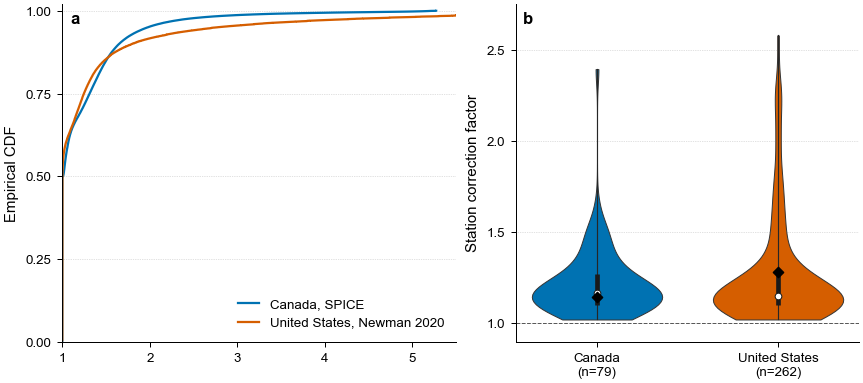

In [8]:
def draw_station_violins(ax):
    sns.violinplot(
        data=stations,
        x="short",
        y="station_factor",
        hue="short",
        order=SHORT,
        hue_order=SHORT,
        palette=PALETTE,
        cut=0,
        inner=None,
        linewidth=0.6,
        saturation=1,
        density_norm="width",
        width=0.72,
        legend=False,
        ax=ax,
    )
    for index, spec in enumerate(COUNTRIES):
        values = stations.loc[stations["key"] == spec["key"], "station_factor"].to_numpy()
        q1, median, q3 = np.percentile(values, [25, 50, 75])
        ax.plot([index, index], [values.min(), values.max()], color="0.15", lw=0.7, zorder=3)
        ax.plot([index, index], [q1, q3], color="0.1", lw=2.8, zorder=4, solid_capstyle="butt")
        ax.scatter([index], [median], s=16, c="white", edgecolors="0.1", linewidths=0.6, zorder=5)
        ax.scatter(
            [index],
            [daily[spec["key"]]["pooled_factor"]],
            s=18,
            c="black",
            marker="D",
            zorder=6,
        )
    ax.axhline(1, color="0.35", lw=0.6, ls="--", zorder=1)
    ax.set_ylim(0.9, 2.75)
    ax.set_yticks([1.0, 1.5, 2.0, 2.5])
    ax.set_ylabel("Station correction factor")
    counts = stations.groupby("key").size()
    ax.set_xticks(range(len(COUNTRIES)))
    ax.set_xticklabels([f"{spec['short']}\n(n={counts[spec['key']]})" for spec in COUNTRIES])
    style_distribution_axis(ax)


def draw_factor_ecdf(ax):
    for spec in COUNTRIES:
        sample = daily[spec["key"]]
        values = np.sort(sample["corrected"][sample["wet"]] / sample["original"][sample["wet"]])
        probability = np.arange(1, len(values) + 1) / len(values)
        ax.step(values, probability, where="post", color=spec["color"], lw=1.35, label=spec["label"])
    ax.set_xlim(1, 5.5)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Wet-day correction factor")
    ax.set_ylabel("Empirical CDF")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.legend(frameon=False, loc="lower right", handlelength=1.6)
    style_distribution_axis(ax)


fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), constrained_layout=True, gridspec_kw={"width_ratios": [1.15, 1]})
draw_factor_ecdf(axes[0])
draw_station_violins(axes[1])
panel_letter(axes[0], "a")
panel_letter(axes[1], "b")
save_figure(fig, "undercatch_factor_distribution")
plt.show()

### Seasonal cycle

For each station and month, the factor is the median over wet days in that
month, and the addition is the mean monthly total over the 40 years. Lines are
the median station. Bands are the interquartile range across stations.

/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_seasonal_cycle.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_seasonal_cycle.pdf


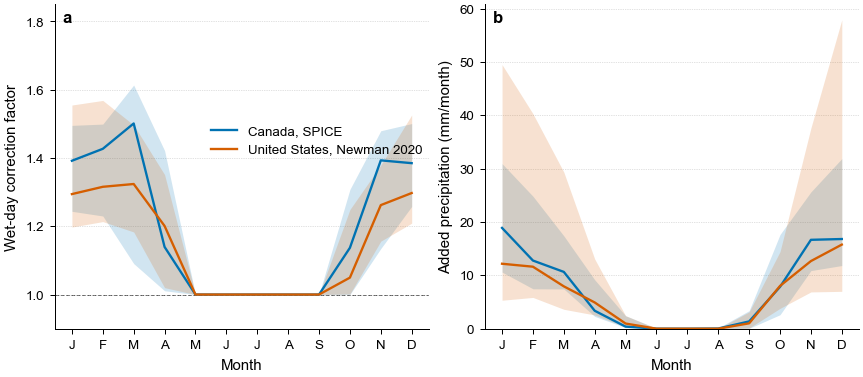

In [9]:
def monthly_station_values(sample):
    months = sample["time"].month.to_numpy()
    n_stations = sample["original"].shape[0]
    factor = np.full((n_stations, 12), np.nan)
    added = np.full((n_stations, 12), np.nan)
    for month in range(1, 13):
        chosen = months == month
        original = sample["original"][:, chosen]
        corrected = sample["corrected"][:, chosen]
        wet = original > 0
        ratio = np.divide(corrected, original, out=np.full_like(original, np.nan), where=wet)
        has_wet = wet.sum(axis=1) > 0
        factor[has_wet, month - 1] = np.nanmedian(ratio[has_wet], axis=1)
        added[:, month - 1] = np.sum(corrected - original, axis=1) / N_YEARS
    return factor, added


fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.15), constrained_layout=True, sharex=True)
month_index = np.arange(12)
for spec in COUNTRIES:
    factor, added = monthly_station_values(daily[spec["key"]])
    for ax, values in ((axes[0], factor), (axes[1], added)):
        mid = np.nanmedian(values, axis=0)
        low = np.nanpercentile(values, 25, axis=0)
        high = np.nanpercentile(values, 75, axis=0)
        ax.fill_between(month_index, low, high, color=spec["color"], alpha=0.18, linewidth=0, zorder=1)
        ax.plot(month_index, mid, color=spec["color"], lw=1.4, label=spec["label"], zorder=2)

axes[0].axhline(1, color="0.35", lw=0.6, ls="--", zorder=0)
axes[0].set_ylabel("Wet-day correction factor")
axes[0].set_ylim(0.9, 1.85)
axes[1].set_ylabel("Added precipitation (mm/month)")
axes[1].set_ylim(0, None)
for ax in axes:
    ax.set_xticks(month_index)
    ax.set_xticklabels(MONTH_LABELS)
    ax.set_xlabel("Month")
    style_distribution_axis(ax)
    ax.set_xlabel("Month")
axes[0].legend(frameon=False, loc="center", bbox_to_anchor=(0.70, 0.58))
panel_letter(axes[0], "a")
panel_letter(axes[1], "b")
save_figure(fig, "undercatch_seasonal_cycle")
plt.show()

### Temperature and wind

Lines are the median wet-day factor. Bands are the interquartile range of the
wet days in that bin. The wind panel is restricted to days at or below 0°C, so
it is not mixed with warm rain. The vertical line on the temperature panel is
the 5°C threshold above which the SPICE correction is turned off. Newman’s snow
fraction is already near zero there as well.

/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_temperature_wind.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_temperature_wind.pdf


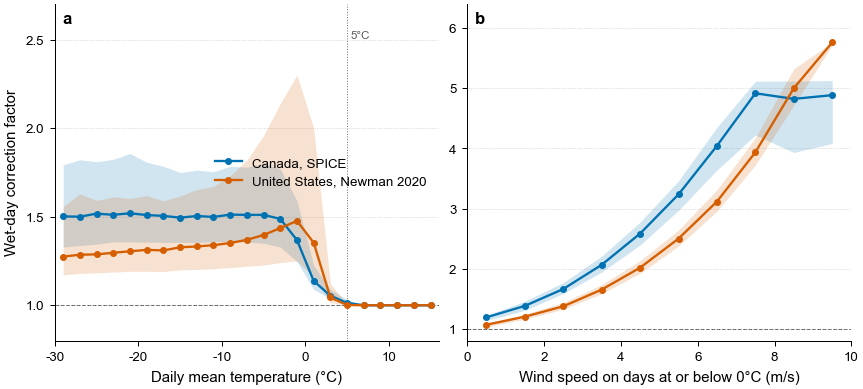

In [10]:
def draw_driver(ax, x_values, y_values, edges, min_count, xlabel):
    for spec, x_sample, y_sample in zip(COUNTRIES, x_values, y_values):
        centers, low, mid, high = binned_curve(x_sample, y_sample, edges, min_count)
        ax.fill_between(centers, low, high, color=spec["color"], alpha=0.18, linewidth=0)
        ax.plot(centers, mid, color=spec["color"], lw=1.4, marker="o", ms=3.2, label=spec["label"])
    ax.axhline(1, color="0.35", lw=0.6, ls="--", zorder=0)
    ax.set_xlabel(xlabel)
    ax.set_ylim(0.8, 6.4)
    ax.set_yticks([1, 2, 3, 4, 5, 6])
    style_distribution_axis(ax)
    ax.set_xlabel(xlabel)


temperature_samples = []
wind_samples = []
factor_cold = []
for spec in COUNTRIES:
    sample = daily[spec["key"]]
    wet = sample["wet"]
    factor = sample["corrected"][wet] / sample["original"][wet]
    temperature = sample["temperature"][wet]
    wind = sample["wind"][wet]
    temperature_samples.append(temperature)
    cold = temperature <= 0
    wind_samples.append(wind[cold])
    factor_cold.append(factor[cold])
    # Keep the warm-day factors paired with temperature for the left panel.
    temperature_samples[-1] = (temperature, factor)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.25), constrained_layout=True)
draw_driver(
    axes[0],
    [pair[0] for pair in temperature_samples],
    [pair[1] for pair in temperature_samples],
    edges=np.arange(-30, 17, 2),
    min_count=400,
    xlabel="Daily mean temperature (°C)",
)
axes[0].set_ylim(0.8, 2.7)
axes[0].set_yticks([1, 1.5, 2, 2.5])
axes[0].axvline(5, color="0.45", lw=0.6, ls=":", zorder=0)
axes[0].text(5.4, 2.55, "5°C", ha="left", va="top", color="0.35", fontsize=7)
axes[0].set_xlim(-30, 16)
axes[0].set_ylabel("Wet-day correction factor")
axes[0].legend(frameon=False, loc="center right")

draw_driver(
    axes[1],
    wind_samples,
    factor_cold,
    edges=np.arange(0, 11, 1),
    min_count=200,
    xlabel="Wind speed on days at or below 0°C (m/s)",
)
axes[1].set_xlim(0, 10)
panel_letter(axes[0], "a")
panel_letter(axes[1], "b")
save_figure(fig, "undercatch_temperature_wind")
plt.show()

### Elevation

Each point is a station. The line is the median in elevation bins of 0–100,
100–300, 300–600, 600–1000, and 1000–1600 m, drawn when a bin has at least 6
stations. Spearman’s rank correlation uses every complete station.

Canada increase_pct: Spearman ρ = 0.33
United States increase_pct: Spearman ρ = -0.29
Canada added_mm_yr: Spearman ρ = -0.10
United States added_mm_yr: Spearman ρ = -0.33
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_vs_elevation.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_vs_elevation.pdf


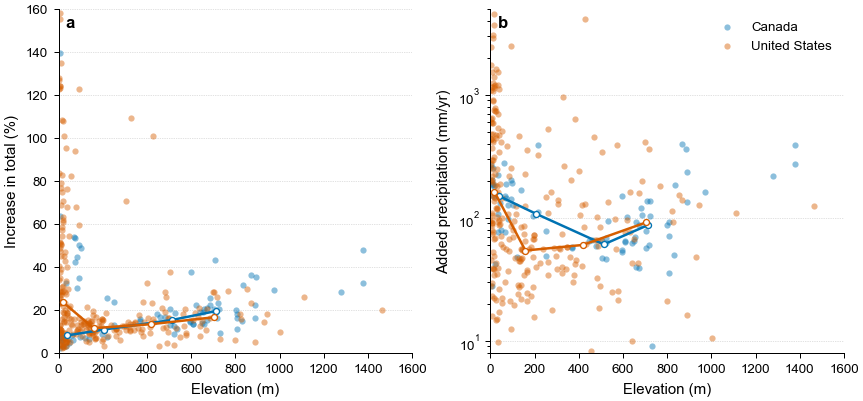

In [11]:
def elevation_bins(elevation, values, edges, min_count=6):
    centers = []
    medians = []
    for lower, upper in zip(edges[:-1], edges[1:]):
        if upper == edges[-1]:
            chosen = (elevation >= lower) & (elevation <= upper)
        else:
            chosen = (elevation >= lower) & (elevation < upper)
        if int(chosen.sum()) < min_count:
            centers.append(np.nan)
            medians.append(np.nan)
        else:
            centers.append(float(np.median(elevation[chosen])))
            medians.append(float(np.median(values[chosen])))
    return np.asarray(centers), np.asarray(medians)


edges = np.array([0, 100, 300, 600, 1000, 1600])
metrics = [
    ("increase_pct", "Increase in total (%)", False),
    ("added_mm_yr", "Added precipitation (mm/yr)", True),
]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.35), constrained_layout=True, sharex=True)
for ax, (column, ylabel, log_scale), letter in zip(axes, metrics, "ab"):
    for spec in COUNTRIES:
        part = stations.loc[stations["key"] == spec["key"]]
        elevation = part["elevation_m"].to_numpy()
        values = part[column].to_numpy()
        ax.scatter(elevation, values, s=14, c=spec["color"], alpha=0.45, linewidths=0, label=spec["short"], zorder=2)
        centers, medians = elevation_bins(elevation, values, edges)
        ax.plot(centers, medians, color=spec["color"], lw=1.5, marker="o", ms=3.6,
                markerfacecolor="white", markeredgecolor=spec["color"], markeredgewidth=0.8, zorder=3)
        rho = pd.Series(elevation).corr(pd.Series(values), method="spearman")
        print(f"{spec['short']} {column}: Spearman ρ = {rho:.2f}")
    ax.set_xlabel("Elevation (m)")
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, 1600)
    style_distribution_axis(ax)
    ax.set_xlabel("Elevation (m)")
    panel_letter(ax, letter)
    if log_scale:
        ax.set_yscale("log")
        ax.set_ylim(8, 5000)

axes[0].set_ylim(0, 160)
axes[1].legend(frameon=False, loc="upper right")
save_figure(fig, "undercatch_vs_elevation")
plt.show()

### Station maps

Same drawing order as the DEM station maps in `static_data_visualization.ipynb`:
the domain DEM in `Greys`, the coastline and the Canada–United States border in
black, then the gauges. Color scales stop at 80% and at 400 mm/yr so the basin
is not scaled to a few coastal gauges. Gauges above those caps take the top
color. The summary table has the uncensored range.

In [12]:
with rasterio.open(DEM_PATH) as dem_source:
    left, bottom, right, top = dem_source.bounds
    out_height = int(round((top - bottom) / 0.025))
    out_width = int(round((right - left) / 0.025))
    dem = dem_source.read(1, out_shape=(out_height, out_width), resampling=Resampling.average)

dem = dem.astype("float32")
dem[dem < -50] = np.nan
dem_extent = [left, right, bottom, top]
dem_vmax = float(np.nanpercentile(dem, 99))
print(f"DEM {dem.shape[1]} x {dem.shape[0]} cells, elevation color scale 0 to {dem_vmax:.0f} m")

map_box = box(left, bottom, right, top)
coastline = gpd.clip(gpd.read_file(COAST_PATH, bbox=(left, bottom, right, top)), map_box)
countries = gpd.read_file(COUNTRIES_PATH)
countries = countries.loc[countries["ISO"].isin(["US", "CA"]), ["ISO", "geometry"]].to_crs(4326)
countries = gpd.clip(countries, map_box)
united_states = countries.loc[countries["ISO"] == "US"].geometry.unary_union
canada = countries.loc[countries["ISO"] == "CA"].geometry.unary_union
border = gpd.GeoSeries([united_states.boundary.intersection(canada.boundary)], crs="EPSG:4326")

DEM 1680 x 720 cells, elevation color scale 0 to 2041 m


/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_station_maps.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/yrb_undercatch/undercatch_station_maps.pdf


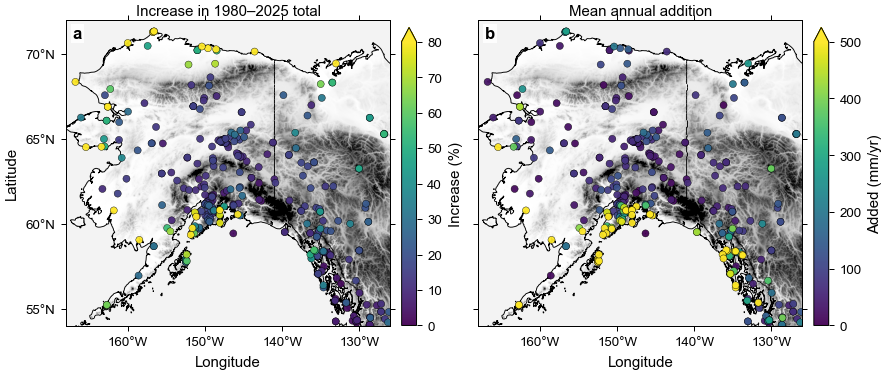

In [15]:
def plot_dem_metric(ax, values, vmin, vmax, title):
    terrain = mpl.colormaps["Greys"].copy()
    terrain.set_bad("#f3f3f3")
    ax.imshow(
        np.ma.masked_invalid(dem),
        extent=dem_extent,
        cmap=terrain,
        vmin=0,
        vmax=dem_vmax,
        interpolation="bilinear",
        origin="upper",
        zorder=0,
    )
    coastline.plot(ax=ax, color="black", linewidth=0.55, zorder=2)
    border.plot(ax=ax, color="black", linewidth=0.55, zorder=2)

    order = np.argsort(values)
    artist = ax.scatter(
        stations["longitude"].to_numpy()[order],
        stations["latitude"].to_numpy()[order],
        c=np.asarray(values)[order],
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        s=18,
        alpha=0.95,
        edgecolors="black",
        linewidths=0.25,
        zorder=3,
    )
    ax.set_xlim(dem_extent[0], dem_extent[1])
    ax.set_ylim(dem_extent[2], dem_extent[3])
    latitude_center = 0.5 * (dem_extent[2] + dem_extent[3])
    ax.set_aspect(1.0 / np.cos(np.deg2rad(latitude_center)))
    ax.set_title(title, pad=3)
    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.yaxis.set_major_locator(MultipleLocator(5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _pos: f"{abs(value):.0f}°W"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _pos: f"{value:.0f}°N"))
    ax.tick_params(direction="out", length=3, width=0.6, top=True, right=True)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.6)
    return artist


fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.85), constrained_layout=True)
increase = plot_dem_metric(axes[0], stations["increase_pct"], 0, 80, "Increase in 1980–2025 total")
addition = plot_dem_metric(axes[1], stations["added_mm_yr"], 0, 500, "Mean annual addition")
panel_letter(axes[0], "a", pad_box=True)
panel_letter(axes[1], "b", pad_box=True)
axes[0].set_ylabel("Latitude")
axes[1].tick_params(labelleft=False)
for ax in axes:
    ax.set_xlabel("Longitude")

for artist, axis, label in (
    (increase, axes[0], "Increase (%)"),
    (addition, axes[1], "Added (mm/yr)"),
):
    color_scale = fig.colorbar(artist, ax=axis, fraction=0.046, pad=0.02, extend="max")
    color_scale.set_label(label)
    color_scale.outline.set_linewidth(0.6)
    color_scale.ax.tick_params(length=3, width=0.6)

save_figure(fig, "undercatch_station_maps")
plt.show()

### Reading the figures

The adjustment is a cold-season, wind-driven increase. Through June–September
the factor sits on 1. In winter the median wet day is raised by about a third,
and windy days below freezing are raised by a factor of two to five. Canada’s
SPICE correction rises faster with wind at moderate speeds. The Newman
adjustment in the United States has the longer tail, past a factor of five.

About half of wet days are unchanged, so the wet-day median factor is essentially
1. The totals still move. At the median gauge the 40-year precipitation total
increases by roughly 15%, or on the order of 70–90 mm/yr. Pooled across gauges,
the United States increase is larger than the median gauge because the wettest
stations are also the ones corrected most.

Those stations are the windy, low-elevation coasts. The percent-increase map and
the added-millimetre map both light up the same coastal gauges, and the addition
falls off toward the interior and with elevation in the United States. In Canada
the relative correction is somewhat larger at higher gauges, but those gauges
are drier, so the added millimetres do not increase with elevation.